## Experiment 4: K-Means Clustering on the Iris Dataset

**Aim:** Cluster the iris data with K-Means and choose the number of clusters using the elbow method.

In [1]:
# A52 Dipanshu Ambilkar
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

In [2]:
X, species = load_iris(return_X_y=True)
print("Shape:", X.shape)

Shape: (150, 4)


In [3]:
print("First row:", X[0])
print("Species labels present:", sorted(set(species)))

First row: [5.1 3.5 1.4 0.2]
Species labels present: [np.int64(0), np.int64(1), np.int64(2)]


In [4]:
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=7)
    km.fit(X)
    inertias.append(km.inertia_)
print("Inertias for k=1..10:", [round(v) for v in inertias])

Inertias for k=1..10: [681, 152, 79, 57, 46, 39, 34, 30, 28, 26]


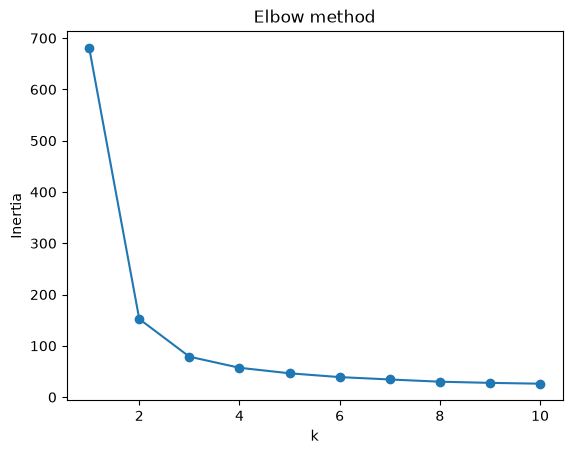

In [5]:
plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.show()

In [6]:
km = KMeans(n_clusters=3, n_init=10, random_state=7)
print("Model created with k = 3 (elbow point)")

Model created with k = 3 (elbow point)


In [7]:
labels = km.fit_predict(X)
print("Cluster sizes:", [sum(labels == c) for c in range(3)])

Cluster sizes: [np.int64(50), np.int64(62), np.int64(38)]


In [8]:
print("Cluster centers:")
print(km.cluster_centers_.round(2))

Cluster centers:
[[5.01 3.43 1.46 0.25]
 [5.9  2.75 4.39 1.43]
 [6.85 3.07 5.74 2.07]]


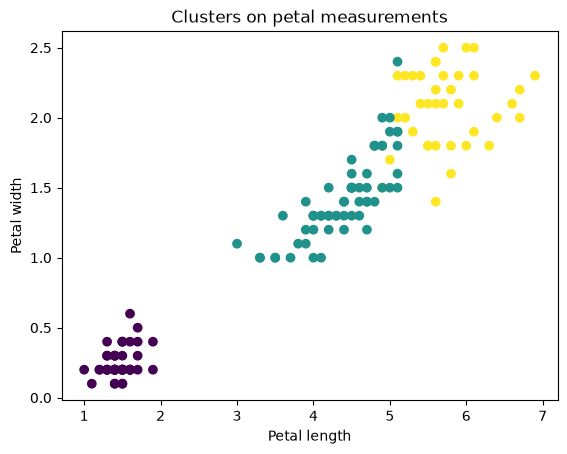

In [9]:
plt.scatter(X[:, 2], X[:, 3], c=labels)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.title("Clusters on petal measurements")
plt.show()

In [10]:
for c in range(3):
    counts = [sum((labels == c) & (species == s)) for s in range(3)]
    print(f"Cluster {c}: species counts {counts}")

Cluster 0: species counts [np.int64(50), np.int64(0), np.int64(0)]
Cluster 1: species counts [np.int64(0), np.int64(48), np.int64(14)]
Cluster 2: species counts [np.int64(0), np.int64(2), np.int64(36)]
